# STORY 4: HOW MUCH DO WE GET PAID?

**Chanice Mckenzie · DATA 608**


"Data practitioner" covers several occupations, but job title and state can change the annual average wage substantially. This story moves from the role-level picture to a state-by-role comparison, then highlights where geography creates the widest spread.

**Source:** [U.S. Bureau of Labor Statistics, Occupational Employment and Wage Statistics (OEWS)](https://www.bls.gov/oes/), accessed through the [BLS Public Data API v2](https://www.bls.gov/developers/api_signature_v2.htm). These are **annual mean wage estimates**, not median pay, offers, or take-home salaries. Data are requested live; the notebook displays the latest year actually returned. Some occupation–state combinations may be suppressed or unavailable.

**Occupation mapping.** Job advertisements use titles such as “data analyst” or “data engineer” inconsistently. To avoid inventing exact equivalences, this analysis uses five *official occupational categories*: Data Scientists (15-2051), Database Architects (15-1241), Computer Systems Analysts (15-1211), Operations Research Analysts (15-2031), and Statisticians (15-2041). These are **proxies for overlapping data-practitioner roles**, not a complete taxonomy.

## 1 · Retrieve and validate salary data from the BLS API

The code constructs official OEWS series IDs for each state and occupation, requests annual mean wages in batches, and keeps the latest available estimate. A retry strategy handles transient API errors; a clear exception is raised if the API does not return enough usable data. The API can be rate-limited, so avoid repeatedly rerunning this cell.

In [14]:
import sys, subprocess, importlib.util
for package in ["requests", "pandas", "numpy", "matplotlib", "seaborn"]:
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import requests, pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import time, math
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180, "font.size": 11})
NAVY, TEAL, CORAL, GREY = "#17324d", "#087f8c", "#df6b57", "#65758b"
ROLES = {
    "Data Scientist": "152051", "Database Architect": "151241",
    "Computer Systems Analyst": "151211", "Operations Research Analyst": "152031",
    "Statistician": "152041"
}
STATES = {
 "Alabama":"01","Alaska":"02","Arizona":"04","Arkansas":"05","California":"06","Colorado":"08",
 "Connecticut":"09","Delaware":"10","Florida":"12","Georgia":"13","Hawaii":"15","Idaho":"16",
 "Illinois":"17","Indiana":"18","Iowa":"19","Kansas":"20","Kentucky":"21","Louisiana":"22",
 "Maine":"23","Maryland":"24","Massachusetts":"25","Michigan":"26","Minnesota":"27","Mississippi":"28",
 "Missouri":"29","Montana":"30","Nebraska":"31","Nevada":"32","New Hampshire":"33","New Jersey":"34",
 "New Mexico":"35","New York":"36","North Carolina":"37","North Dakota":"38","Ohio":"39","Oklahoma":"40",
 "Oregon":"41","Pennsylvania":"42","Rhode Island":"44","South Carolina":"45","South Dakota":"46",
 "Tennessee":"47","Texas":"48","Utah":"49","Vermont":"50","Virginia":"51","Washington":"53",
 "West Virginia":"54","Wisconsin":"55","Wyoming":"56"
}
API_URL = "https://api.bls.gov/publicAPI/v2/timeseries/data/"
# OEUS + seven-digit state area + six-digit industry + six-digit SOC + two-digit data type
# 04 = annual mean wage, all industries = 000000.
lookup = {f"OEUS{fips}00000" + "000000" + soc + "04": (state, role)
          for state, fips in STATES.items() for role, soc in ROLES.items()}
series_ids = list(lookup)
print(f"Requesting {len(series_ids)} occupation/state series in batches of 25...")

def request_batch(ids):
    payload = {"seriesid": ids}
    last_error = None
    for attempt in range(4):
        try:
            resp = requests.post(API_URL, json=payload, timeout=70,
                                 headers={"User-Agent": "DATA608-Colab-SalaryStory/1.0"})
            resp.raise_for_status()
            body = resp.json()
            if body.get("status") != "REQUEST_SUCCEEDED":
                raise RuntimeError(f"BLS API status: {body.get('status')}; {body.get('message')}")
            return body.get("Results", {}).get("series", [])
        except (requests.RequestException, ValueError, RuntimeError) as exc:
            last_error = exc
            if attempt < 3: time.sleep(2 ** attempt + 1)
    raise RuntimeError(f"BLS API request failed after retries: {last_error}")

records = []
for batch_number, start in enumerate(range(0, len(series_ids), 25), 1):
    batch = request_batch(series_ids[start:start + 25])
    for item in batch:
        sid = item.get("seriesID", "")
        if sid not in lookup: continue
        state, role = lookup[sid]
        for observation in item.get("data", []):
            if observation.get("period") not in ("A01", "M13"): continue
            try: wage = float(str(observation["value"]).replace(",", ""))
            except (ValueError, TypeError, KeyError): continue
            if wage > 0:
                records.append({"State": state, "Role": role, "Year": int(observation["year"]), "Mean wage": wage})
    print(f"Batch {batch_number}/{math.ceil(len(series_ids)/25)} complete")
    time.sleep(0.8)

if not records:
    raise RuntimeError("No valid annual mean wage observations returned. Check API availability and OEWS series coverage.")
raw = pd.DataFrame(records)
# Select the most recent common year with meaningful coverage, rather than mixing survey years.
coverage = raw.groupby("Year").size().sort_index(ascending=False)
valid_years = coverage[coverage >= 50]
if valid_years.empty:
    raise RuntimeError(f"Too few state/role observations to chart reliably: {coverage.to_dict()}")
year = int(valid_years.index[0])
df = (raw.loc[raw["Year"].eq(year)].sort_values("Year")
      .drop_duplicates(["State", "Role"], keep="last").copy())
print(f"\nSelected OEWS year: {year} | Available combinations: {len(df)}/250")
print(f"States represented: {df.State.nunique()} | Roles represented: {df.Role.nunique()}")
display(df.head(8))
# Export a reproducible snapshot, in addition to keeping the API as the live source.
df.to_csv(f"data_practitioner_bls_oews_{year}.csv", index=False)


Requesting 250 occupation/state series in batches of 25...
Batch 1/10 complete
Batch 2/10 complete
Batch 3/10 complete
Batch 4/10 complete
Batch 5/10 complete
Batch 6/10 complete
Batch 7/10 complete
Batch 8/10 complete
Batch 9/10 complete
Batch 10/10 complete

Selected OEWS year: 2025 | Available combinations: 237/250
States represented: 50 | Roles represented: 5


,State,Role,Year,Mean wage
0,Alabama,Data Scientist,2025,105180.0
1,Alabama,Database Architect,2025,128680.0
2,Alabama,Computer Systems Analyst,2025,107430.0
3,Alabama,Operations Research Analyst,2025,117850.0
4,Alabama,Statistician,2025,79820.0
5,Alaska,Data Scientist,2025,89810.0
6,Alaska,Database Architect,2025,127400.0
7,Alaska,Computer Systems Analyst,2025,95750.0


## 2 · Role matters: average pay is not uniform across data occupations

**Chart message:** Compare the typical *state-level annual mean wage* across five roles first, before introducing the geographic differences. Each dot represents the **median of the available state mean wages**, not a national BLS wage estimate. This avoids incorrectly calling an unweighted state average a national salary.

**Why this chart:** A sorted dot plot makes the occupational ranking easy to scan; direct labels reduce the need to read an axis. The accent color identifies the highest role-level midpoint.

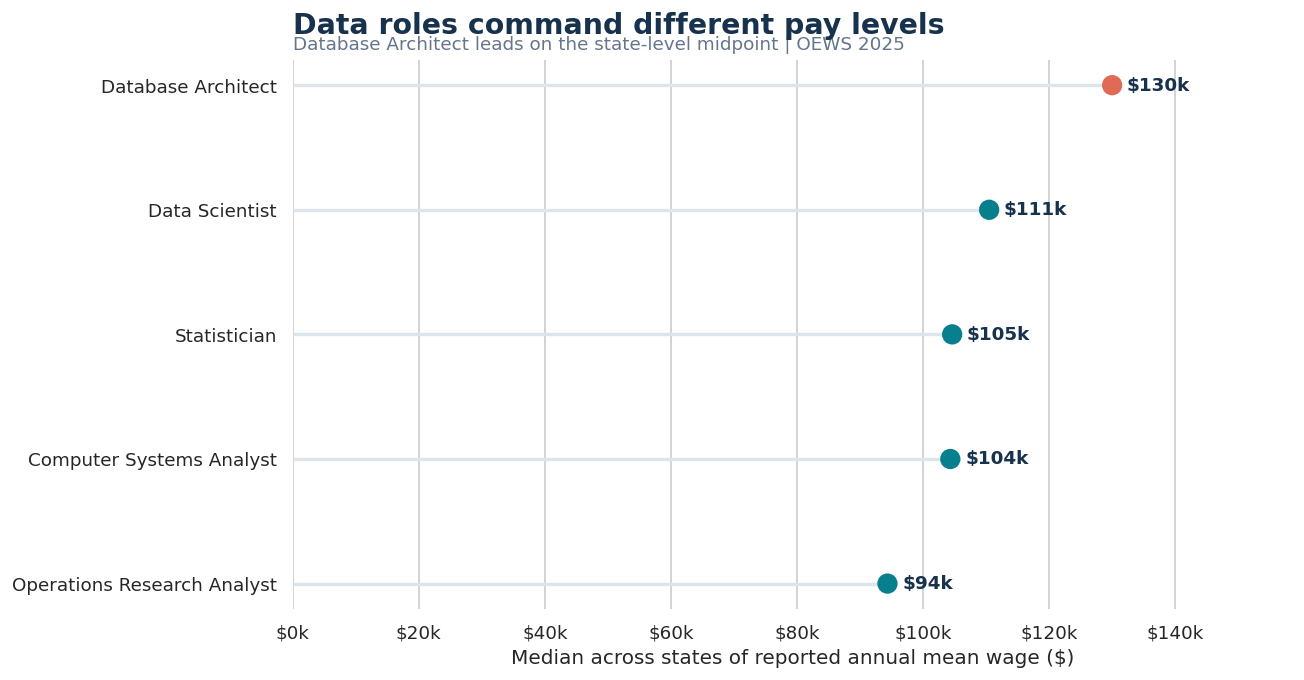

In [15]:
role_mid = df.groupby("Role")["Mean wage"].median().sort_values()
fig, ax = plt.subplots(figsize=(11, 5.8))
colors = [CORAL if role == role_mid.idxmax() else TEAL for role in role_mid.index]
ax.hlines(range(len(role_mid)), 0, role_mid.values, color="#dce5ec", lw=2)
ax.scatter(role_mid.values, range(len(role_mid)), s=125, c=colors, zorder=3)
for i, value in enumerate(role_mid.values):
    ax.text(value + role_mid.max() * .018, i, f"${value/1000:,.0f}k", va="center", weight="bold", color=NAVY)
ax.set_yticks(range(len(role_mid)), role_mid.index)
ax.set_xlim(0, role_mid.max() * 1.22)
ax.set_xlabel("Median across states of reported annual mean wage ($)")
ax.set_title("Data roles command different pay levels", loc="left", fontsize=17, weight="bold", color=NAVY, pad=16)
ax.text(0, 1.02, f"{role_mid.idxmax()} leads on the state-level midpoint | OEWS {year}", transform=ax.transAxes, color=GREY)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x/1000:.0f}k"))
sns.despine(left=True, bottom=True); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()


## 3 · Geography reshuffles the ranking

**Chart message:** The same role does not receive the same average wage in every state. Darker cells mean higher reported annual mean wages; blank cells indicate no usable published estimate.

**Why this chart:** A heatmap shows the full state-by-role matrix without requiring 250 separate bars. Sorting states by their average of available role wages makes broad high- and low-wage patterns easier to see. This state ranking is descriptive and does **not** adjust for occupation mix or cost of living.

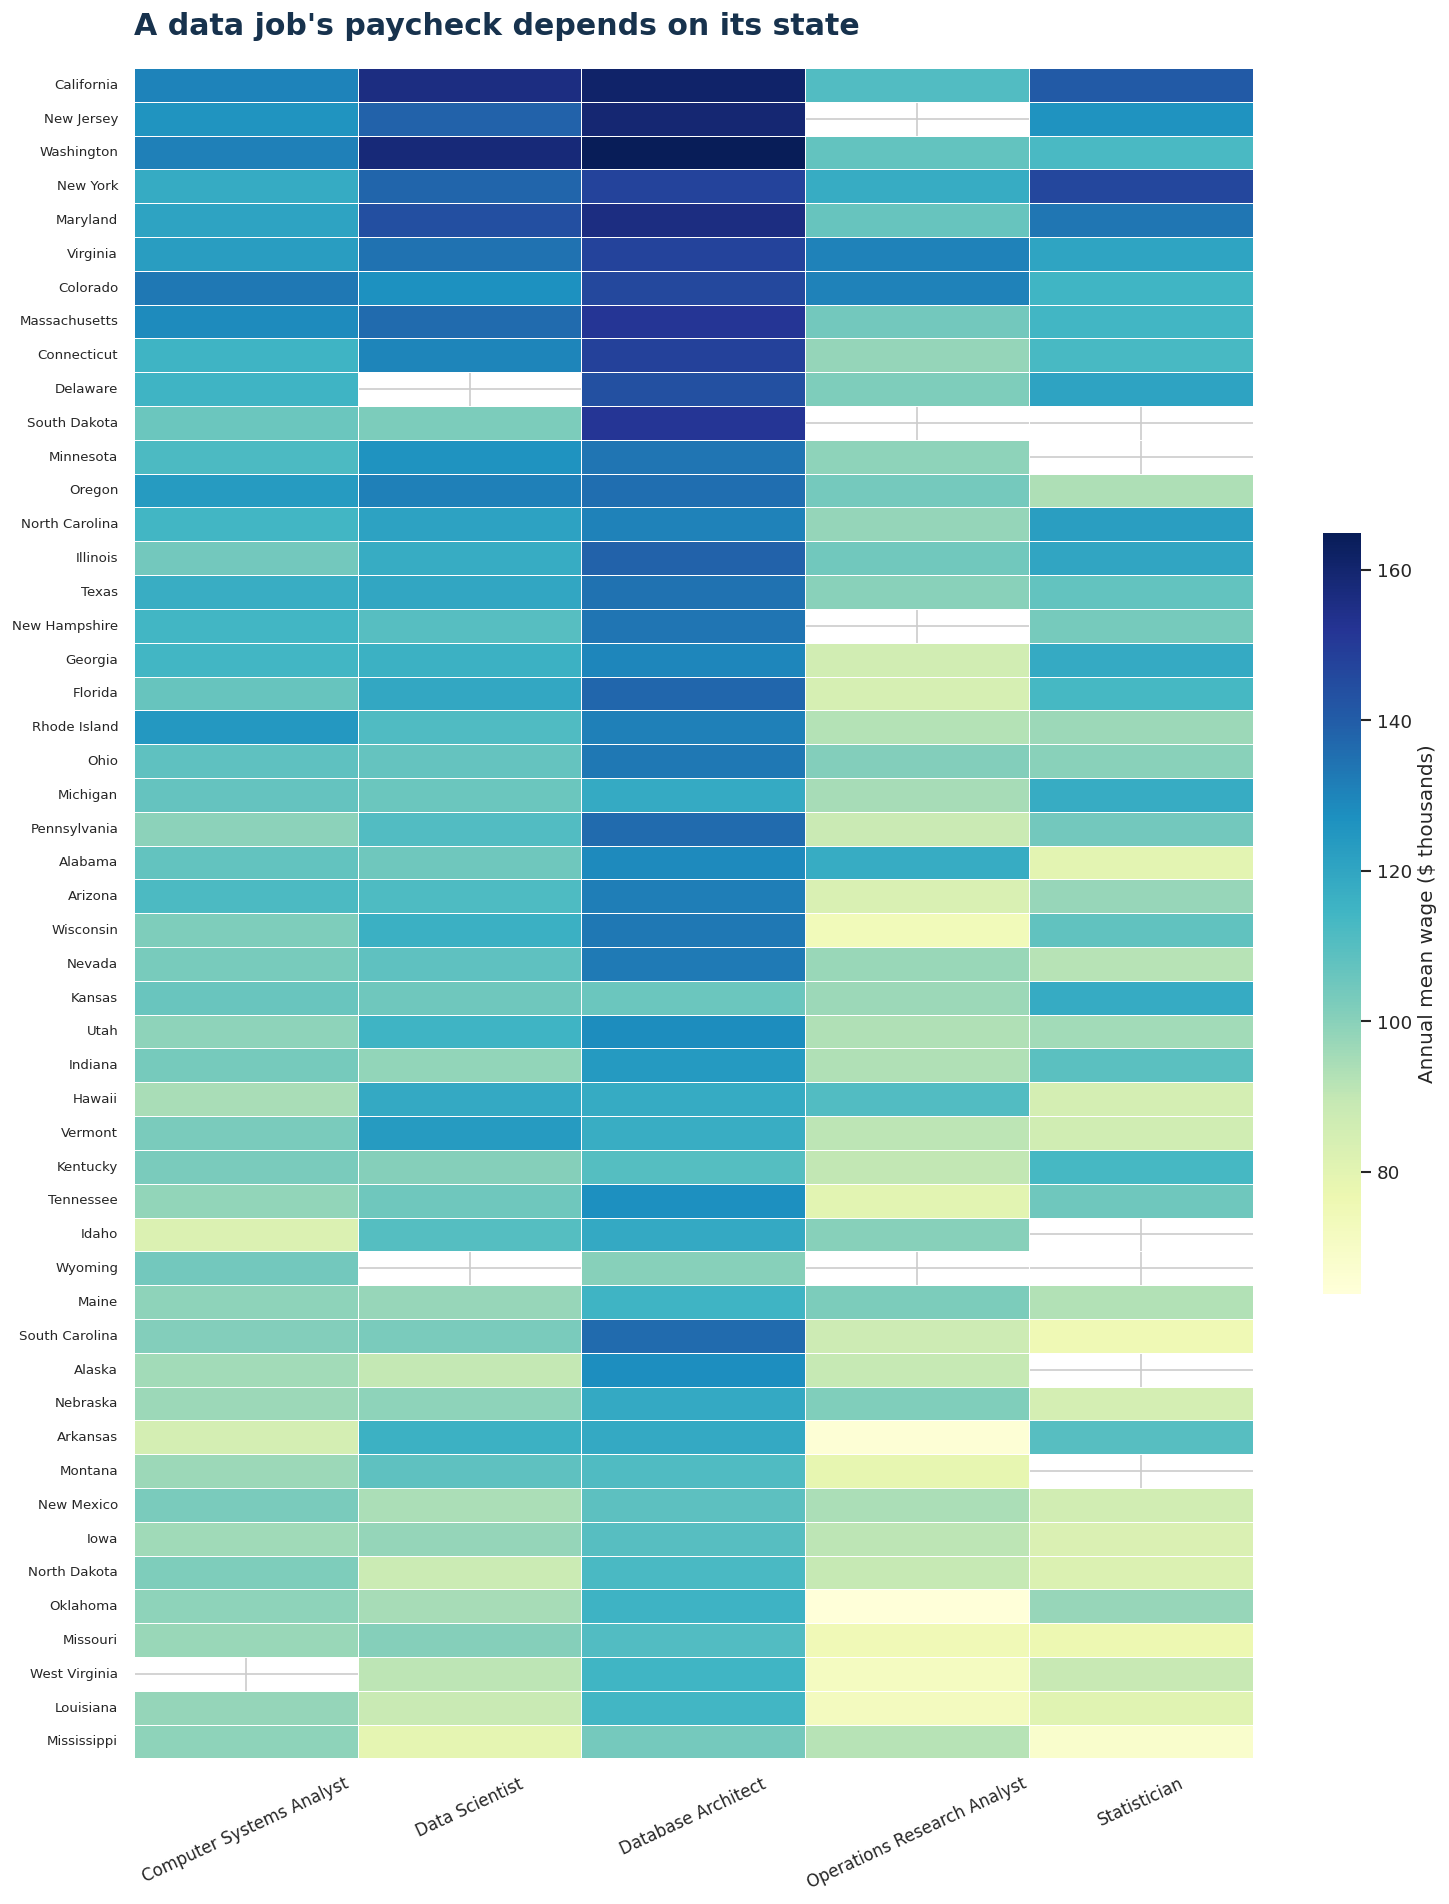

In [16]:
matrix = df.pivot(index="State", columns="Role", values="Mean wage")
matrix = matrix.loc[matrix.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(13, 16))
sns.heatmap(matrix / 1000, cmap="YlGnBu", linewidths=.35, linecolor="white",
            cbar_kws={"label": "Annual mean wage ($ thousands)", "shrink": .45}, ax=ax,
            mask=matrix.isna())
ax.set_title("A data job's paycheck depends on its state", loc="left", fontsize=18, weight="bold", color=NAVY, pad=20)
ax.set_xlabel(""); ax.set_ylabel("")
ax.tick_params(axis="x", rotation=25, labelsize=10); ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()


## 4 · The geographic pay gap is larger for some roles

**Chart message:** The spread between the highest- and lowest-paying *reporting states* varies by occupation. This is a **nominal wage spread**, not a causal effect of moving states.

**Why this chart:** A connected range (dumbbell) chart communicates both endpoints and the size of each role's state-level range more directly than a second bar chart. Endpoint labels highlight the most important extremes.

In [21]:
# Install the package for U.S. state abbreviations
!pip -q install us

import us

# Convert full state names to two-letter abbreviations
df["State"] = df["State"].apply(
    lambda state: us.states.lookup(state).abbr
    if us.states.lookup(state) else state
)

# Verify the conversion
print(df["State"].unique()[:10])

['AL' 'AK' 'AZ' 'AR' 'CA' 'CO' 'CT' 'DE' 'FL' 'GA']


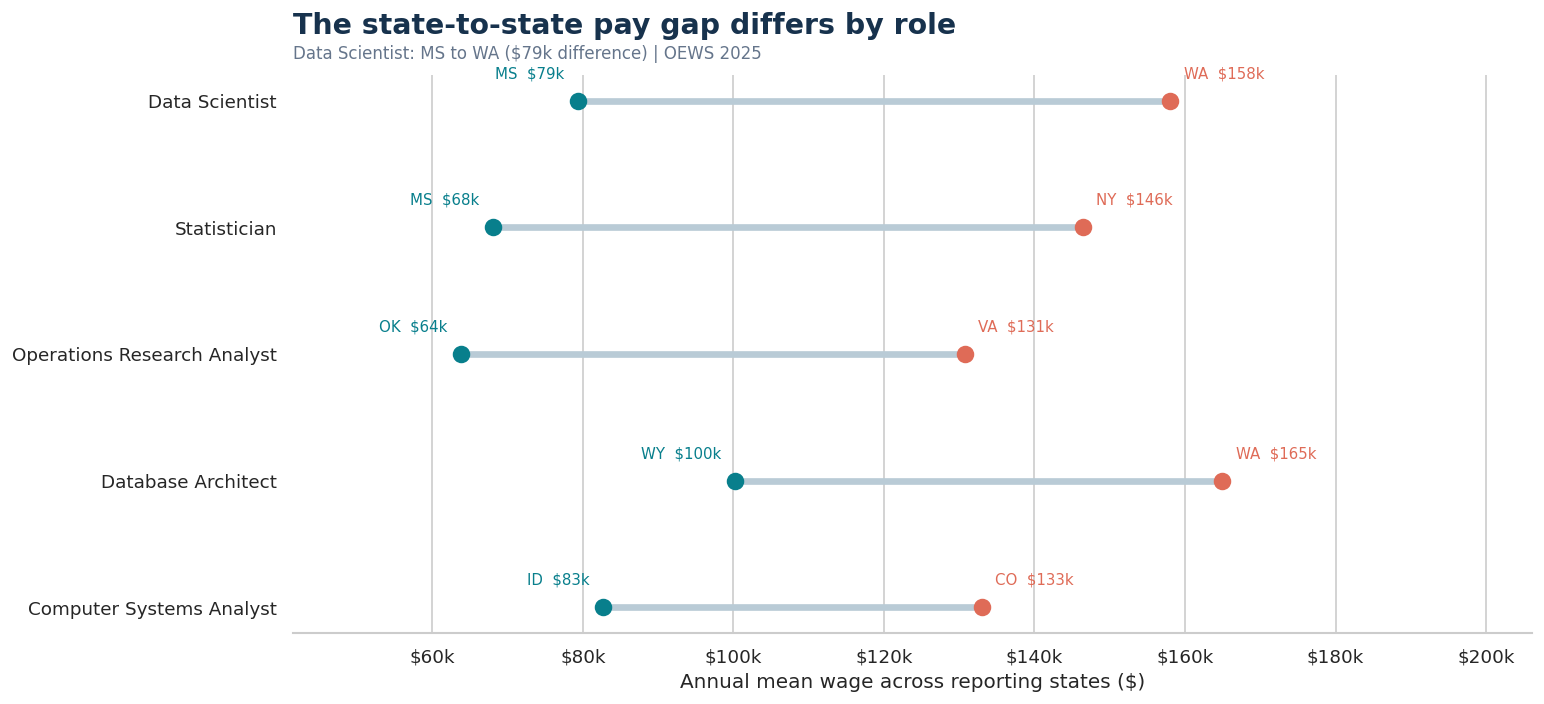

In [22]:
# Find the lowest- and highest-paying state for each occupation
min_rows = df.loc[df.groupby("Role")["Mean wage"].idxmin()]
max_rows = df.loc[df.groupby("Role")["Mean wage"].idxmax()]

# Create the salary range table
ranges = df.groupby("Role")["Mean wage"].agg(["min", "max", "count"])

# Add state abbreviations
ranges["min_state"] = min_rows.set_index("Role")["State"]
ranges["max_state"] = max_rows.set_index("Role")["State"]

# Calculate salary spread
ranges["spread"] = ranges["max"] - ranges["min"]
ranges = ranges.sort_values("spread")

# Create dumbbell chart
fig, ax = plt.subplots(figsize=(13, 6))

for i, (role, r) in enumerate(ranges.iterrows()):

    # Connecting line
    ax.plot(
        [r["min"], r["max"]],
        [i, i],
        color="#b9cbd6",
        lw=4,
        zorder=1
    )

    # Lowest salary
    ax.scatter(r["min"], i, s=90, color=TEAL, zorder=3)

    # Highest salary
    ax.scatter(r["max"], i, s=90, color=CORAL, zorder=3)

    # Label lowest salary and state
    ax.text(
        r["min"] - 1800,
        i + 0.18,
        f"{r['min_state']}  ${r['min']/1000:.0f}k",
        ha="right",
        fontsize=9,
        color=TEAL
    )

    # Label highest salary and state
    ax.text(
        r["max"] + 1800,
        i + 0.18,
        f"{r['max_state']}  ${r['max']/1000:.0f}k",
        ha="left",
        fontsize=9,
        color=CORAL
    )

# Formatting
ax.set_yticks(range(len(ranges)), ranges.index)

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"${x/1000:.0f}k")
)

ax.set_xlabel("Annual mean wage across reporting states ($)")

ax.set_title(
    "The state-to-state pay gap differs by role",
    loc="left",
    fontsize=17,
    weight="bold",
    color=NAVY,
    pad=25
)

# Kicker
largest_role = ranges["spread"].idxmax()
largest = ranges.loc[largest_role]

ax.text(
    0, 1.03,
    f"{largest_role}: {largest['min_state']} to "
    f"{largest['max_state']} "
    f"(${largest['spread']/1000:,.0f}k difference) | OEWS {year}",
    transform=ax.transAxes,
    color=GREY,
    fontsize=10
)

# Extra space for state labels
ax.set_xlim(
    max(0, ranges["min"].min() * 0.65),
    ranges["max"].max() * 1.25
)

sns.despine(left=True)
ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()



## 5 · Four states reveal how the same role changes in context

**Chart message:** Side-by-side role comparisons make geographic differences tangible for readers who are considering specific labor markets. California, New York, Texas, and Florida are illustrative comparisons, not the four highest-paying states.

**Why this chart:** Small-multiple horizontal bars make four state profiles comparable using a shared scale. This adds chart diversity without sacrificing readability; a highlighted Data Scientist bar anchors the comparison.

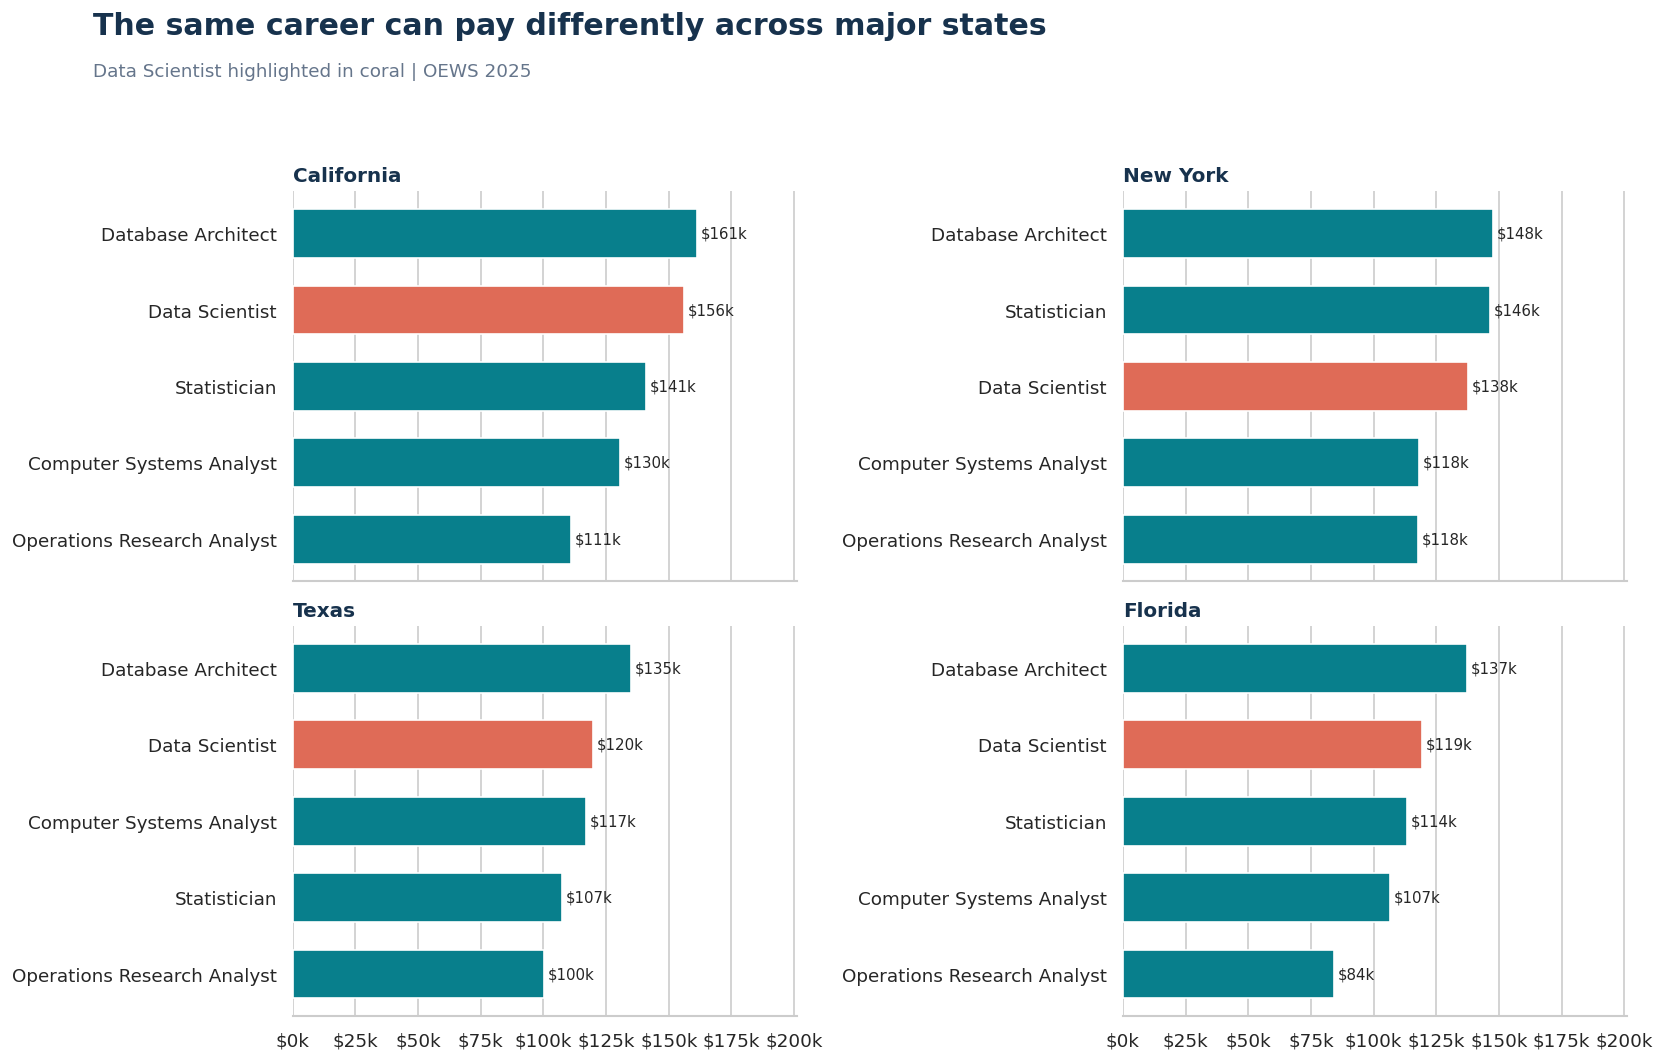

In [19]:
focus = ["California", "New York", "Texas", "Florida"]
selected = df[df.State.isin(focus)].copy()
maxw = df["Mean wage"].max() * 1.22
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
for ax, state in zip(axes.flat, focus):
    subset = selected[selected.State.eq(state)].sort_values("Mean wage")
    if subset.empty:
        ax.text(.5,.5,"No reported data", ha="center", va="center", transform=ax.transAxes)
    else:
        cols = [CORAL if role == "Data Scientist" else TEAL for role in subset.Role]
        ax.barh(subset.Role, subset["Mean wage"], color=cols, height=.64)
        for i, wage in enumerate(subset["Mean wage"]):
            ax.text(wage + 1500, i, f"${wage/1000:.0f}k", va="center", fontsize=9)
    ax.set_title(state, loc="left", weight="bold", color=NAVY)
    ax.set_xlim(0, maxw); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x/1000:.0f}k"))
    ax.grid(axis="y", visible=False); sns.despine(ax=ax, left=True)
fig.suptitle("The same career can pay differently across major states", x=.06, ha="left", fontsize=18, weight="bold", color=NAVY)
fig.text(.06, .92, f"Data Scientist highlighted in coral | OEWS {year}", color=GREY)
plt.tight_layout(rect=[0,0,1,.9]); plt.show()


## 6 · Conclusions, limitations, and next steps

The story deliberately progresses from **role ranking → all-state comparison → size of geographic variation → recognizable state examples**. Together, the charts address the assignment's two dimensions: **occupation** and **state**. The following summary is computed from the actual API response, so it does not invent rankings in advance.

In [20]:
top_role = role_mid.idxmax()
widest_role = ranges["spread"].idxmax()
leaders = (df.sort_values("Mean wage", ascending=False)
           .groupby("Role", as_index=False).first()[["Role", "State", "Mean wage"]])
display(Markdown(f"""**Key findings (OEWS {year}):** Across reporting states, **{top_role}** has the highest midpoint of state-level mean wages (${role_mid.max():,.0f}). **{widest_role}** has the widest observed high-to-low state spread (${ranges.loc[widest_role, 'spread']:,.0f}). These comparisons describe published wage estimates, not what any individual worker will earn."""))
display(leaders.rename(columns={"State": "Highest-reporting state", "Mean wage": "Annual mean wage ($)"}).style.format({"Annual mean wage ($)": "${:,.0f}"}))
print(f"Missing state-role combinations: {250-len(df)} of 250")


**Key findings (OEWS 2025):** Across reporting states, **Database Architect** has the highest midpoint of state-level mean wages ($130,035). **Data Scientist** has the widest observed high-to-low state spread ($78,750). These comparisons describe published wage estimates, not what any individual worker will earn.

,Role,Highest-reporting state,Annual mean wage ($)
0,Computer Systems Analyst,Colorado,"$132,980"
1,Data Scientist,Washington,"$158,040"
2,Database Architect,Washington,"$164,930"
3,Operations Research Analyst,Virginia,"$130,720"
4,Statistician,New York,"$146,430"


Missing state-role combinations: 13 of 250


### Interpretation and responsible use

- **Definitions matter:** BLS occupation codes are standardized categories; a “data analyst” job posting might map to different categories depending on duties. A direct job-title salary comparison is not available from these codes alone.
- **Average is not typical:** OEWS **annual mean wages** can differ from medians and do not include self-employed workers. The first chart uses a **median of state means**, explicitly labeled as such, to summarize geography without pretending it is the national mean.
- **Coverage and precision:** Suppressed or missing state-role estimates are not zeros. This notebook excludes them and reports missing combinations. Wage estimates have sampling uncertainty.
- **Geographic context:** Dollar wages are **not cost-of-living adjusted**. A high-paying state may also be expensive to live in.
- **Next steps:** Add regional price parity or cost-of-living data, explore metro areas, compare multiple survey years where occupational definitions are consistent, and cross-check job-posting titles with SOC descriptions.

**Sources and methods:** [BLS OEWS](https://www.bls.gov/oes/), [BLS API documentation](https://www.bls.gov/developers/api_signature_v2.htm), [BLS occupational classifications](https://www.bls.gov/soc/). Data accessed live when the notebook is run. API requests require an internet connection and are subject to BLS availability and request limits.
